# 03. Пороги по цене ошибки, многоуровневая реакция, сравнение вариантов
**Задачи №17, №18, №32 (Р1).** Пункты кейса 1 и 4.

**№17.** Порог по полной цене ошибок: цена пропуска = сумма хищения, цена ложного ограничения = обращение в КЦ + недополученный доход («Допущения», стр. 75).
Сравниваем «один порог для всех» и «свой порог для каждого сегмента».

**№18.** Пять уровней реакции: пропустить → предупреждение → доп. подтверждение → звонок банка → приостановка по 161-ФЗ.
Ложные сигналы и ошибочно ограниченные операции считаем **отдельно**, как требует кейс (с. 10).

**№32.** Четыре варианта решения по единой сетке: только правила / только ML / гибрид с единым порогом / гибрид + многоуровневая реакция.

**Вход:** `sparkov_scores.csv.gz` из ноутбука 02 (в Kaggle: Add Input → Your Work → ноутбук 02).

> Обязательные меры 161-ФЗ (12 признаков ЦБ, база ЦБ, период охлаждения) срабатывают **до** модели и не ослабляются.
> На данных Sparkov их нельзя воспроизвести (нет базы ЦБ), поэтому слой правил представлен прокси: «крупная сумма в ночное время».

## 0. Допущения
Значения из листа «Допущения» (Р4), номер строки — в комментарии.
Параметры с пометкой **Р1** — допущения модели реакции без публичного источника; их влияние проверено в разделе «Чувствительность».

### Общие функции
Сплит по времени, метрики по формулам кейса, цена ошибки, симуляция реакции. Ячейка записывает модуль `antifraud_utils.py` рядом с ноутбуком.

In [1]:
%%writefile antifraud_utils.py
"""
Общие функции для ноутбуков команды (Хакатон ВТБ, задача №6).

Метрики считаются строго по формулам кейса (с. 10):
  точность выявления          = TP / (TP + FP)
  доля ложных сигналов        = FP / (TP + FP)
  FPR (ложные среди законных) = FP / (FP + TN)
  полнота обнаружения         = TP / (TP + FN)
Дополнительно: полнота по сумме (какая доля похищаемых денег остановлена).

Этот же код вставлен первой ячейкой в каждый ноутбук, чтобы ноутбуки
запускались на Kaggle без дополнительных файлов.
"""
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score


# ---------------------------------------------------------------- сплит
def time_split(df, time_col, fracs=(0.6, 0.2, 0.2)):
    """Сплит по времени: train — самые ранние операции, test — самые поздние.
    Случайный сплит запрещён: он подмешивает «будущее» в обучение и завышает метрики."""
    t = df[time_col]
    q1 = t.quantile(fracs[0])
    q2 = t.quantile(fracs[0] + fracs[1])
    train = df[t <= q1]
    valid = df[(t > q1) & (t <= q2)]
    test = df[t > q2]
    return train, valid, test


# ---------------------------------------------------------------- история клиента без утечки
def past_stats(df, group_cols, time_col, value_col, lag=0, window=None):
    """Статистики по ПРОШЛЫМ операциям группы (клиент, клиент+категория, получатель...).

    Для строки с временем t учитываются операции той же группы со временем < t − lag
    (и, если задано window, ≥ t − lag − window). Текущая операция и будущее не учитываются.
    lag=0      — онлайн-признак (поток операций доступен сразу)
    lag=86400  — «ночной профиль»: данные приходят с задержкой до суток (условие кейса)
    Возвращает DataFrame (cnt, sum, mean, std) в порядке индекса df. Векторизовано.
    """
    g = df.groupby(group_cols, sort=False).ngroup().to_numpy().astype(np.int64)
    t = df[time_col].to_numpy().astype(np.int64)
    v = df[value_col].to_numpy().astype(float)
    t = t - t.min()
    big = np.int64(t.max() + lag + (window or 0) + 2)
    key = g * big + t
    order = np.argsort(key, kind="mergesort")
    ks, vs = key[order], v[order]
    cs = np.r_[0.0, np.cumsum(vs)]
    cs2 = np.r_[0.0, np.cumsum(vs ** 2)]
    gs = g[order] * big                                   # начало «окна» группы на оси ключей
    hi = np.searchsorted(ks, ks - lag, side="left")       # строки со временем < t − lag
    lo = np.searchsorted(ks, gs, side="left")             # первая строка группы
    if window is not None:
        lo = np.maximum(lo, np.searchsorted(ks, ks - lag - window, side="left"))
    hi = np.maximum(hi, lo)
    cnt = (hi - lo).astype(float)
    s = cs[hi] - cs[lo]
    s2 = cs2[hi] - cs2[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = np.where(cnt > 0, s / cnt, np.nan)
        var = np.where(cnt > 1, (s2 - s ** 2 / cnt) / (cnt - 1), np.nan)
    out = np.empty((len(df), 4))
    out[order] = np.c_[cnt, s, mean, np.sqrt(np.clip(var, 0, None))]
    return pd.DataFrame(out, index=df.index, columns=["cnt", "sum", "mean", "std"])


# ---------------------------------------------------------------- метрики
def metrics(y, score, threshold, amount=None):
    """Все метрики кейса при заданном пороге. y — 1 мошенничество, 0 законная."""
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)
    pred = score >= threshold
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    res = {
        "n": len(y),
        "n_fraud": int(y.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "false_signal_share": fp / (tp + fp) if tp + fp else np.nan,
        "alert_rate": (tp + fp) / len(y),
        "roc_auc": roc_auc_score(y, score) if 0 < y.sum() < len(y) else np.nan,
        "pr_auc": average_precision_score(y, score) if y.sum() > 0 else np.nan,
        "threshold": threshold,
    }
    if amount is not None:
        amount = np.asarray(amount, dtype=float)
        fraud_amt = amount[y == 1].sum()
        caught = amount[(y == 1) & pred].sum()
        res["fraud_amount"] = fraud_amt
        res["caught_amount"] = caught
        res["missed_amount"] = fraud_amt - caught
        res["amount_recall"] = caught / fraud_amt if fraud_amt else np.nan
    return res


def metrics_by_group(df, group_col, y_col, score_col, threshold, amount_col=None):
    """Метрики по сегментам. threshold — число или dict {сегмент: порог}."""
    rows = []
    for g, part in df.groupby(group_col, observed=True):
        thr = threshold[g] if isinstance(threshold, dict) else threshold
        m = metrics(part[y_col], part[score_col], thr,
                    part[amount_col] if amount_col else None)
        m[group_col] = g
        rows.append(m)
    return pd.DataFrame(rows).set_index(group_col)


def threshold_for_fpr(y, score, target_fpr):
    """Порог, при котором FPR на этих данных не превышает target_fpr."""
    y = np.asarray(y).astype(int)
    legit = np.sort(np.asarray(score, dtype=float)[y == 0])[::-1]
    k = int(np.floor(target_fpr * len(legit)))
    # флагуем только то, что строго выше k-го законного скора (корректно и при одинаковых скорах)
    return float(np.nextafter(legit[min(k, len(legit) - 1)], np.inf))


# ---------------------------------------------------------------- цена ошибки
def cost_curve(y, score, amount, cost_fp, loss_share=1.0):
    """Полная цена ошибок для КАЖДОГО возможного порога (точный перебор).

    Цена пропуска (FN)  = сумма хищения × loss_share
    Цена ложного (FP)   = cost_fp (обработка + ожидаемый отказ от операции)
    Возвращает DataFrame: threshold, TP, FP, missed_amount, cost.
    """
    y = np.asarray(y).astype(int)
    s = np.asarray(score, dtype=float)
    a = np.asarray(amount, dtype=float)
    order = np.argsort(-s, kind="mergesort")
    s, y, a = s[order], y[order], a[order]
    tp = np.cumsum(y)
    fp = np.cumsum(1 - y)
    caught = np.cumsum(a * y)
    total_fraud_amt = (a * y).sum()
    # позиции, где score меняется: порог = s[i], флагуем всё с индексом <= i
    last = np.r_[s[1:] != s[:-1], True]
    idx = np.where(last)[0]
    out = pd.DataFrame({
        "threshold": s[idx],
        "TP": tp[idx], "FP": fp[idx],
        "missed_amount": total_fraud_amt - caught[idx],
    })
    # вариант «не флагуем ничего»
    out = pd.concat([pd.DataFrame({"threshold": [np.inf], "TP": [0], "FP": [0],
                                   "missed_amount": [total_fraud_amt]}), out],
                    ignore_index=True)
    out["cost"] = out["missed_amount"] * loss_share + out["FP"] * cost_fp
    return out


def best_threshold(y, score, amount, cost_fp, loss_share=1.0):
    cc = cost_curve(y, score, amount, cost_fp, loss_share)
    return float(cc.loc[cc["cost"].idxmin(), "threshold"])


def best_threshold_by_group(df, group_col, y_col, score_col, amount_col,
                            cost_fp, loss_share=1.0):
    """Свой порог для каждого сегмента. cost_fp может быть dict по сегментам."""
    thr = {}
    for g, part in df.groupby(group_col, observed=True):
        c = cost_fp[g] if isinstance(cost_fp, dict) else cost_fp
        thr[g] = best_threshold(part[y_col], part[score_col], part[amount_col], c, loss_share)
    return thr


def total_cost(y, score, amount, threshold, cost_fp, loss_share=1.0):
    m = metrics(y, score, threshold, amount)
    return m["missed_amount"] * loss_share + m["FP"] * cost_fp


# ---------------------------------------------------------------- многоуровневая реакция
# Уровень реакции (tier) — dict:
#   name           название
#   stop_fraud     доля мошеннических операций, которые этот уровень останавливает
#   legit_blocked  доля законных операций, которые на этом уровне не состоятся
#                  (приостановка или отказ клиента) — «ошибочно ограниченные» по кейсу
#   legit_churn    доля законных клиентов, которые после этого снижают активность
#   legit_kc       доля законных клиентов, которые обращаются в КЦ
#   op_cost        прямые затраты банка на одну операцию этого уровня, руб. (SMS, звонок)
# Экономика (econ) — dict:
#   loss_share     доля суммы хищения, которая считается потерей (цена пропуска)
#   kc_cost        стоимость одного обращения в КЦ, руб.
#   churn_value    потеря дохода от одного клиента, снизившего активность, руб.

_TIER_KEYS = ["stop_fraud", "legit_blocked", "legit_churn", "legit_kc", "op_cost"]


def _tier_arrays(tiers):
    return {k: np.array([t[k] for t in tiers], dtype=float) for k in _TIER_KEYS}


def legit_cost(tier, econ):
    """Цена одного ложного сигнала на этом уровне для законного клиента и банка, руб."""
    return tier["op_cost"] + tier["legit_kc"] * econ["kc_cost"] + tier["legit_churn"] * econ["churn_value"]


def choose_tier(p, amount, tiers, econ, allowed=None):
    """Для каждой операции — уровень реакции с максимальной ожидаемой выгодой.

    Выгода = p·сумма·loss_share·stop_fraud                              (сохранённые деньги)
           − (1−p)·(legit_kc·kc_cost + legit_churn·churn_value)         (цена ложного сигнала)
           − op_cost                                                    (работа банка)
    p — откалиброванная вероятность мошенничества.
    allowed — необязательная маска (n_ops × n_tiers): какие уровни разрешены для операции.
    """
    T = _tier_arrays(tiers)
    p = np.asarray(p, dtype=float)[:, None]
    a = np.asarray(amount, dtype=float)[:, None]
    saved = p * a * econ["loss_share"] * T["stop_fraud"][None, :]
    friction = (1 - p) * (T["legit_kc"] * econ["kc_cost"] + T["legit_churn"] * econ["churn_value"])[None, :]
    benefit = saved - friction - T["op_cost"][None, :]
    if allowed is not None:
        benefit = np.where(np.asarray(allowed, dtype=bool), benefit, -np.inf)
    return benefit.argmax(axis=1)


def simulate_reaction(y, amount, tier_idx, tiers, econ, client_id=None):
    """Ожидаемые последствия выбранных уровней на РАЗМЕЧЕННЫХ данных.

    Ложные сигналы и ошибочно ограниченные операции считаются отдельно (кейс, с. 10):
      false_signals       — законные операции, получившие любую реакцию выше «пропустить»
      wrongly_restricted  — законные операции, которые в итоге не состоялись
    """
    T = _tier_arrays(tiers)
    y = np.asarray(y).astype(int)
    a = np.asarray(amount, dtype=float)
    ti = np.asarray(tier_idx)
    stop = T["stop_fraud"][ti]
    blocked = T["legit_blocked"][ti]
    fr, lg = y == 1, y == 0
    res = {
        "ops": len(y),
        "fraud_ops": int(fr.sum()),
        "fraud_amount": a[fr].sum(),
        "prevented_amount": (a * stop)[fr].sum(),
        "stolen_amount": (a * (1 - stop))[fr].sum(),
        "fraud_stopped_exp": stop[fr].sum(),          # ожидаемое число остановленных хищений (TP)
        "fraud_flagged": int((ti[fr] > 0).sum()),     # хищения, получившие любую реакцию
        "false_signals": int((ti[lg] > 0).sum()),
        "false_signal_rate": float((ti[lg] > 0).mean()),
        "wrongly_restricted_exp": blocked[lg].sum(),
        "wrongly_restricted_rate": float(blocked[lg].mean()),
        "kc_inbound_exp": T["legit_kc"][ti][lg].sum(),
        "ops_cost": T["op_cost"][ti].sum(),
        "churn_clients_exp": T["legit_churn"][ti][lg].sum(),
    }
    res["kc_cost"] = res["kc_inbound_exp"] * econ["kc_cost"]
    res["churn_cost"] = res["churn_clients_exp"] * econ["churn_value"]
    res["amount_recall"] = res["prevented_amount"] / res["fraud_amount"] if res["fraud_amount"] else np.nan
    if client_id is not None:
        cid = np.asarray(client_id)[lg]
        # вероятность, что у клиента за период было хотя бы одно ошибочное ограничение
        log_ok = pd.Series(np.log1p(-np.clip(blocked[lg], 0, 0.999999))).groupby(cid).sum()
        res["clients"] = int(len(np.unique(np.asarray(client_id))))
        res["clients_wrongly_restricted_exp"] = float((1 - np.exp(log_ok)).sum())
    return res


def tier_table(y, tier_idx, tiers):
    """Сколько законных и мошеннических операций попало на каждый уровень."""
    y = np.asarray(y).astype(int)
    df = pd.DataFrame({"tier": [tiers[i]["name"] for i in tier_idx], "y": y})
    t = df.groupby("tier")["y"].agg(ops="size", fraud="sum")
    t["legit"] = t["ops"] - t["fraud"]
    return t.reindex([x["name"] for x in tiers]).fillna(0).astype(int)


def fmt_rub(x):
    return f"{x/1e6:,.2f} млн руб.".replace(",", " ")


Overwriting antifraud_utils.py


In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from antifraud_utils import *
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

# На Kaggle датасеты лежат в /kaggle/input, результаты пишем в /kaggle/working
DATA_DIR = os.environ.get("DATA_DIR", "/kaggle/input")
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working" if os.path.exists("/kaggle/working") else "output")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name, dirs=(DATA_DIR, OUT_DIR)):
    for d in dirs:
        hits = sorted(glob.glob(os.path.join(d, "**", name), recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} не найден. В Kaggle: Add Input → подключите нужный датасет/ноутбук")


In [3]:
AVG_OBDS_RUB = 18_600                 # стр. 9: средняя сумма ОБДС, 2025, Банк России (кейс, с. 7)

KC_COST = 181                          # стр. 29: стоимость одного обращения в КЦ, руб.
INCOME_PER_MONTH = 977                 # стр. 33: средний доход банка с активного клиента в месяц, руб.
LOW_MONTHS, LOW_SHARE = 3, 0.3         # стр. 55, 56: месяцев сниженной активности и доля теряемого дохода
CHURN_VALUE = INCOME_PER_MONTH * LOW_MONTHS * LOW_SHARE   # 879,3 руб. на одного клиента, снизившего активность

P_ABANDON_AFTER_BLOCK = 0.15           # стр. 30: доля отказавшихся от законной операции после ограничения
P_KC_AFTER_BLOCK = 0.5                 # стр. 54: доля ложно ограниченных, обращающихся в КЦ
CONFIRM_PASS = 0.75                    # стр. 32: доля законных, проходящих подтверждение без обращения в поддержку
P_ABANDON_CONFIRM = 0.005              # стр. 73: доля бросивших платёж на подтверждении
CONFIRM_COST = 1.0                     # стр. 74: стоимость одного подтверждения для банка, руб.
NPS_GAP = -30                          # стр. 31: NPS клиентов с ошибочной блокировкой ниже на 30 п.п.

ECON = dict(loss_share=1.0,            # цена пропуска = вся сумма хищения (кейс, с. 9–10)
            kc_cost=KC_COST, churn_value=CHURN_VALUE)

TIERS_BASE = [
    dict(name="Пропустить", stop_fraud=0.00, legit_blocked=0, legit_churn=0, legit_kc=0, op_cost=0),
    # Р1: push-предупреждение в приложении; отказ вдвое реже, чем на подтверждении
    dict(name="Предупреждение", stop_fraud=0.20, legit_blocked=P_ABANDON_CONFIRM / 2,
         legit_churn=P_ABANDON_CONFIRM / 2, legit_kc=0, op_cost=0),
    # стр. 32, 73, 74; эффективность против мошенничества — Р1
    dict(name="Доп. подтверждение", stop_fraud=0.45, legit_blocked=P_ABANDON_CONFIRM,
         legit_churn=P_ABANDON_CONFIRM, legit_kc=1 - CONFIRM_PASS, op_cost=CONFIRM_COST),
    # Р1: исходящий звонок оператора по стоимости обращения в КЦ (стр. 29)
    dict(name="Звонок банка", stop_fraud=0.75, legit_blocked=0.01, legit_churn=0.01, legit_kc=0, op_cost=KC_COST),
    # стр. 30, 54: приостановка на 2 дня; эффективность — Р1
    dict(name="Приостановка 161-ФЗ", stop_fraud=0.95, legit_blocked=1, legit_churn=P_ABANDON_AFTER_BLOCK,
         legit_kc=P_KC_AFTER_BLOCK, op_cost=0),
]
SUSPEND = len(TIERS_BASE) - 1

# Р1: у 60+ под давлением звонящего текстовое предупреждение работает хуже, живой звонок — лучше
SEGMENT_OVERRIDES = {"60+": {"Предупреждение": dict(stop_fraud=0.10), "Звонок банка": dict(stop_fraud=0.85)}}
MIN_FRAUD_PER_SEGMENT = 30             # меньше хищений в сегменте на валидации — порог ненадёжен, берём общий

def tiers_for(segment):
    out = []
    for t in TIERS_BASE:
        t = dict(t); t.update(SEGMENT_OVERRIDES.get(segment, {}).get(t["name"], {})); out.append(t)
    return out

tiers_view = pd.DataFrame(TIERS_BASE).set_index("name")
tiers_view["цена ложного сигнала, руб."] = [legit_cost(t, ECON) for t in TIERS_BASE]
print(f"Цена ложного ограничения: {legit_cost(TIERS_BASE[SUSPEND], ECON):.1f} руб. (сверка: «Допущения», стр. 75 = 222)")
print(f"Цена ложного подтверждения: {legit_cost(TIERS_BASE[2], ECON):.2f} руб. (сверка: «Допущения», стр. 79 = 50,65)")
tiers_view

Цена ложного ограничения: 222.4 руб. (сверка: «Допущения», стр. 75 = 222)
Цена ложного подтверждения: 50.65 руб. (сверка: «Допущения», стр. 79 = 50,65)


,stop_fraud,legit_blocked,legit_churn,legit_kc,op_cost,"цена ложного сигнала, руб."
name,,,,,,
Пропустить,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Предупреждение,0.2000,0.0025,0.0025,0.0000,0.0000,2.1982
Доп. подтверждение,0.4500,0.0050,0.0050,0.2500,1.0000,50.6465
Звонок банка,0.7500,0.0100,0.0100,0.0000,181.0000,189.7930
Приостановка 161-ФЗ,0.9500,1.0000,0.1500,0.5000,0.0000,222.3950


In [4]:
sc = pd.read_csv(find("sparkov_scores.csv.gz"))
SEGMENTS = ["18–25", "26–59", "60+"]
sc["segment"] = pd.Categorical(sc.segment, categories=SEGMENTS, ordered=True)
AMOUNT_SCALE = AVG_OBDS_RUB / sc.loc[sc.is_fraud == 1, "amt"].mean()
sc["amt_rub"] = sc.amt * AMOUNT_SCALE
sc["hour"] = (sc.t // 3600) % 24
va, te = sc[sc.split == "valid"].copy(), sc[sc.split == "test"].copy()
print(f"Коэффициент перевода сумм: ×{AMOUNT_SCALE:.1f}; средняя законная операция {sc.loc[sc.is_fraud == 0, 'amt_rub'].mean():,.0f} руб.")
print(f"valid: {len(va):,} операций, {va.is_fraud.sum()} хищений;  test: {len(te):,} операций, {te.is_fraud.sum()} хищений")

Коэффициент перевода сумм: ×35.1; средняя законная операция 2,378 руб.
valid: 259,335 операций, 1538 хищений;  test: 555,719 операций, 2145 хищений


## 1. Один порог vs пороги по сегментам (№17)
Срабатывание = приостановка. Пороги подбираются на валидации, оцениваются на тесте.

In [5]:
COST_FP = legit_cost(TIERS_BASE[SUSPEND], ECON)
thr_fpr1 = threshold_for_fpr(va.is_fraud, va.score, 0.01)
thr_single = best_threshold(va.is_fraud, va.score, va.amt_rub, COST_FP, ECON["loss_share"])
thr_seg = best_threshold_by_group(va, "segment", "is_fraud", "score", "amt_rub", COST_FP, ECON["loss_share"])
for s in SEGMENTS:
    if va.loc[va.segment == s, "is_fraud"].sum() < MIN_FRAUD_PER_SEGMENT:
        print(f"{s}: на валидации {va.loc[va.segment == s, 'is_fraud'].sum()} хищений < {MIN_FRAUD_PER_SEGMENT}, используем общий порог")
        thr_seg[s] = thr_single

variants = {"Бейзлайн: FPR ≤ 1%": thr_fpr1, "Один порог по цене ошибки": thr_single, "Пороги по сегментам": thr_seg}
rows = []
for name, thr in variants.items():
    for s in SEGMENTS:
        part = te[te.segment == s]
        t = thr[s] if isinstance(thr, dict) else thr
        m = metrics(part.is_fraud, part.score, t, part.amt_rub)
        m.update(variant=name, segment=s, cost_fp=COST_FP,
                 total_cost=m["missed_amount"] * ECON["loss_share"] + m["FP"] * COST_FP)
        rows.append(m)
by_seg = pd.DataFrame(rows)
total = by_seg.groupby("variant", sort=False)[["n", "n_fraud", "TP", "FP", "FN", "fraud_amount", "caught_amount",
                                                "missed_amount", "total_cost"]].sum()
total["recall"] = total.TP / total.n_fraud
total["FPR"] = total.FP / (total.n - total.n_fraud)
total["precision"] = total.TP / (total.TP + total.FP)
total["amount_recall"] = total.caught_amount / total.fraud_amount
total[["TP", "FP", "FN", "precision", "recall", "FPR", "amount_recall", "missed_amount", "total_cost"]]

,TP,FP,FN,precision,recall,FPR,amount_recall,missed_amount,total_cost
variant,,,,,,,,,
Бейзлайн: FPR ≤ 1%,2124,4821,21,0.3058,0.9902,0.0087,0.9981,"76,173.9369","1,148,340.2319"
Один порог по цене ошибки,2070,578,75,0.7817,0.9650,0.0010,0.9872,"509,601.6278","638,145.9378"
Пороги по сегментам,2087,886,58,0.7020,0.9730,0.0016,0.9897,"411,825.1408","608,867.1108"


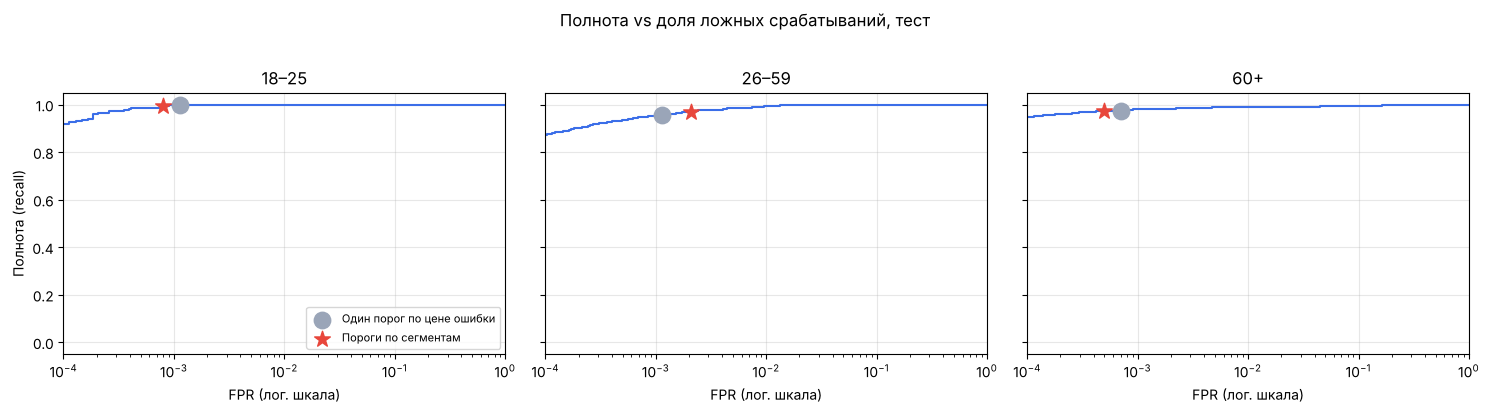

In [6]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, s in zip(ax, SEGMENTS):
    part = te[te.segment == s]
    if part.is_fraud.nunique() < 2:
        a.set_title(f"{s}: в тесте нет хищений"); continue
    fpr, tpr, _ = roc_curve(part.is_fraud, part.score)
    a.plot(fpr, tpr, color="#3b6ee8")
    for name, mk, c in [("Один порог по цене ошибки", "o", "#9aa5b8"), ("Пороги по сегментам", "*", "#e8463b")]:
        r = by_seg[(by_seg.variant == name) & (by_seg.segment == s)].iloc[0]
        a.scatter(r.FPR, r.recall, marker=mk, s=140, color=c, zorder=3, label=name)
    a.set_xscale("log"); a.set_xlim(1e-4, 1); a.set_title(s); a.set_xlabel("FPR (лог. шкала)"); a.grid(alpha=.3)
ax[0].set_ylabel("Полнота (recall)"); ax[0].legend(loc="lower right", fontsize=8)
plt.suptitle("Полнота vs доля ложных срабатываний, тест", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/thresholds_recall_vs_fpr.png", dpi=120, bbox_inches="tight"); plt.show()

## 2. Слой правил (прокси 161-ФЗ)
Правило «крупная сумма в ночное время (22:00–03:59)». Порог суммы подбирается на валидации:
- для варианта «только правила» — минимизируя полную цену ошибок одного правила;
- для гибрида — минимизируя цену ошибок правила **вместе** с моделью (правило ловит то, что пропустила модель).

In [7]:
NIGHT = [22, 23, 0, 1, 2, 3]
CAND = np.unique(np.quantile(va.amt_rub, np.linspace(0.5, 0.9999, 300)))

def rule_flag(df, A):
    return df.hour.isin(NIGHT).to_numpy() & (df.amt_rub.to_numpy() >= A)

def cost_of(df, flag):
    m = metrics(df.is_fraud, flag.astype(float), 0.5, df.amt_rub)
    return m["missed_amount"] * ECON["loss_share"] + m["FP"] * COST_FP

A_rule = min(CAND, key=lambda A: cost_of(va, rule_flag(va, A)))
ml_va = va.score.to_numpy() >= thr_single
A_hyb = min(np.r_[CAND, np.inf], key=lambda A: cost_of(va, rule_flag(va, A) | ml_va))
print(f"Только правила: сумма ≥ {A_rule:,.0f} руб. ночью;  в гибриде: сумма ≥ {A_hyb:,.0f} руб. ночью")

Только правила: сумма ≥ 8,158 руб. ночью;  в гибриде: сумма ≥ inf руб. ночью


## 3. Многоуровневая реакция (№18)
Скор калибруется в вероятность (изотоническая регрессия на валидации). Для каждой операции выбирается уровень с максимальной ожидаемой выгодой:
сохранённые деньги × эффективность уровня − цена ложного сигнала для законного клиента − работа банка.
Срабатывание правила 161-ФЗ всегда ведёт к приостановке.

**Ограничение:** приостановка разрешена только там, где её назначает и текущая схема (скор не ниже порога по цене ошибки).
Ниже порога добавляются мягкие уровни, выше порога часть случаев может смягчиться. Без этого ограничения оптимизация «по деньгам»
начинает приостанавливать больше законных операций: ложное ограничение (222 руб.) много дешевле средней кражи (18,6 тыс. руб.),
а кейс требует снижать и хищения, и ошибочные ограничения.

**До (AS-IS):** правила + модель с единым порогом по цене ошибки, любое срабатывание = приостановка на 2 дня.
**После (TO-BE):** правила → приостановка; остальное — пять уровней по скору, параметры уровней свои для сегмента.

In [8]:
from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(va.score, va.is_fraud)
te["p"] = iso.predict(te.score)
te["rule"] = rule_flag(te, A_hyb)

def tobe_tiers(df, tiers_fn=tiers_for):
    out = pd.Series(0, index=df.index)
    for s in SEGMENTS:
        m = df.segment == s
        allowed = np.ones((m.sum(), len(TIERS_BASE)), bool)
        allowed[:, SUSPEND] = (df.score[m] >= thr_single).to_numpy()
        out[m] = choose_tier(df.p[m], df.amt_rub[m], tiers_fn(s), ECON, allowed)
    out[df.rule] = SUSPEND
    return out

te["tier_asis"] = np.where(te.rule | (te.score >= thr_single), SUSPEND, 0)
te["tier_tobe"] = tobe_tiers(te)

def run(tier_col, df=te, tiers_fn=tiers_for):
    rows = {}
    for s in SEGMENTS:
        part = df[df.segment == s]
        rows[s] = simulate_reaction(part.is_fraud, part.amt_rub, part[tier_col], tiers_fn(s), ECON, part.cc_num)
    r = pd.DataFrame(rows).T
    tot = r.sum()
    legit = tot.ops - tot.fraud_ops
    tot["false_signal_rate"] = tot.false_signals / legit
    tot["wrongly_restricted_rate"] = tot.wrongly_restricted_exp / legit
    tot["amount_recall"] = tot.prevented_amount / tot.fraud_amount
    r.loc["все"] = tot
    r["nps_penalty_pts"] = NPS_GAP * r.clients_wrongly_restricted_exp / r.clients
    r["total_loss"] = r.stolen_amount * ECON["loss_share"] + r.ops_cost + r.kc_cost + r.churn_cost
    return r

asis, tobe = run("tier_asis"), run("tier_tobe")
pd.concat({"AS-IS": tier_table(te.is_fraud, te.tier_asis, TIERS_BASE),
           "TO-BE": tier_table(te.is_fraud, te.tier_tobe, TIERS_BASE)}, axis=1)

AS-IS                 TO-BE              
                        ops fraud   legit     ops fraud   legit
tier                                                           
Пропустить           553071    75  552996  550008    38  549970
Предупреждение            0     0       0    2326    54    2272
Доп. подтверждение        0     0       0     602    19     583
Звонок банка              0     0       0     363     5     358
Приостановка 161-ФЗ    2648  2070     578    2420  2029     391

### До / после

In [9]:
KPI = {
    "stolen_amount": "Похищено, руб.",
    "prevented_amount": "Предотвращено, руб.",
    "amount_recall": "Доля остановленной суммы",
    "fraud_stopped_exp": "Корректно выявлено и остановлено (TP), шт.",
    "false_signals": "Ложные сигналы (законные операции с любой реакцией), шт.",
    "false_signal_rate": "Доля законных операций с сигналом",
    "wrongly_restricted_exp": "Ошибочно ограничено операций, шт.",
    "wrongly_restricted_rate": "Доля ошибочно ограниченных законных операций",
    "kc_inbound_exp": "Обращений в КЦ, шт.",
    "kc_cost": "Затраты КЦ, руб.",
    "ops_cost": "Подтверждения и звонки банка, руб.",
    "churn_cost": "Недополученный доход (снижение активности), руб.",
    "nps_penalty_pts": "Потеря NPS от ошибочных ограничений, п.п.",
    "total_loss": "Итого потери и затраты, руб.",
}
ba = pd.DataFrame({"До (AS-IS)": asis.loc["все", list(KPI)], "После (TO-BE)": tobe.loc["все", list(KPI)]}).astype(float)
ba["Изменение"] = ba["После (TO-BE)"] - ba["До (AS-IS)"]
ba["Изменение, %"] = ba["Изменение"] / ba["До (AS-IS)"].replace(0, np.nan) * 100
ba.index = [KPI[k] for k in ba.index]
ba

,До (AS-IS),После (TO-BE),Изменение,"Изменение, %"
"Похищено, руб.","2,475,232.7386","2,268,478.5190","-206,754.2195",-8.3529
"Предотвращено, руб.","37,346,991.1047","37,553,745.3243","206,754.2195",0.5536
Доля остановленной суммы,0.9378,0.9430,0.0052,0.5536
"Корректно выявлено и остановлено (TP), шт.","1,966.5000","1,949.7500",-16.7500,-0.8518
"Ложные сигналы (законные операции с любой реакцией), шт.",578.0000,"3,604.0000","3,026.0000",523.5294
Доля законных операций с сигналом,0.0010,0.0065,0.0055,523.5294
"Ошибочно ограничено операций, шт.",578.0000,403.1750,-174.8250,-30.2465
Доля ошибочно ограниченных законных операций,0.0010,0.0007,-0.0003,-30.2465
"Обращений в КЦ, шт.",289.0000,341.2500,52.2500,18.0796
"Затраты КЦ, руб.","52,309.0000","61,766.2500","9,457.2500",18.0796


In [10]:
seg_cols = ["amount_recall", "fraud_stopped_exp", "wrongly_restricted_rate", "false_signal_rate", "nps_penalty_pts"]
pd.concat({"До": asis.loc[SEGMENTS, seg_cols], "После": tobe.loc[SEGMENTS, seg_cols]}, axis=1).swaplevel(axis=1).sort_index(axis=1)

amount_recall        false_signal_rate        fraud_stopped_exp            nps_penalty_pts          wrongly_restricted_rate       
                 До  После                До  После                До      После              До    После                      До  После
18–25        0.9500 0.9497            0.0011 0.0049          209.0000   205.2500        -14.4156 -11.1149                  0.0011 0.0008
26–59        0.9309 0.9396            0.0011 0.0073        1,225.5000 1,218.8000        -12.1595  -9.9813                  0.0011 0.0008
60+          0.9479 0.9477            0.0007 0.0048          532.0000   525.7000         -7.8823  -5.1533                  0.0007 0.0004

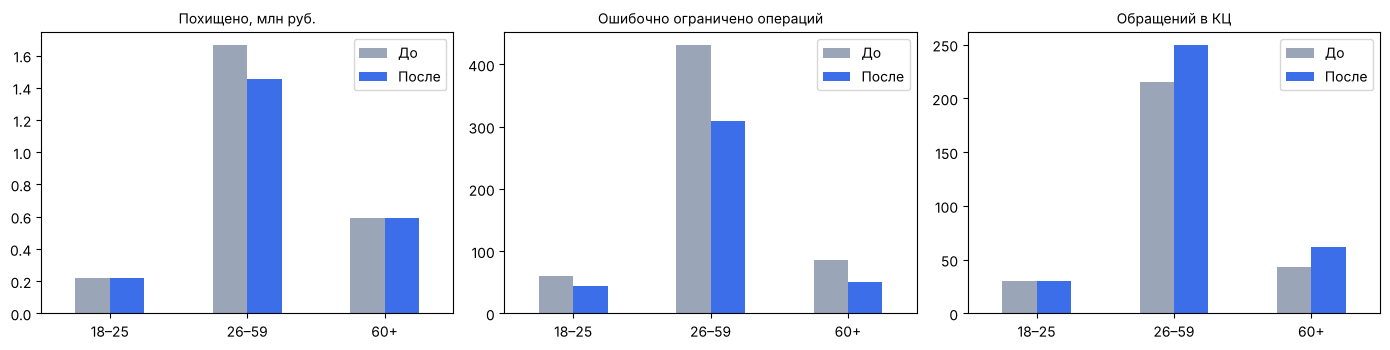

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (col, title) in zip(ax, [("stolen_amount", "Похищено, млн руб."),
                                ("wrongly_restricted_exp", "Ошибочно ограничено операций"),
                                ("kc_inbound_exp", "Обращений в КЦ")]):
    vals = pd.DataFrame({"До": asis.loc[SEGMENTS, col], "После": tobe.loc[SEGMENTS, col]}).astype(float)
    if "руб" in title: vals = vals / 1e6
    vals.plot.bar(ax=a, rot=0, color=["#9aa5b8", "#3b6ee8"]); a.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/reaction_before_after.png", dpi=120); plt.show()

### Чувствительность
Параметры без публичного источника: доля бросивших платёж на подтверждении (стр. 73, сценарии 1% / 0,5% / 0,25%),
доля проходящих подтверждение без звонка (стр. 32, сценарии 65% / 75% / 85%) и эффективность мягких уровней (Р1: ×0,7 / ×1 / ×1,3).

In [12]:
import copy
BASE_TIERS = copy.deepcopy(TIERS_BASE)
sens = []
for abandon in [0.01, 0.005, 0.0025]:
    for pass_rate in [0.65, 0.75, 0.85]:
        for eff in [0.7, 1.0, 1.3]:
            TIERS_BASE[:] = copy.deepcopy(BASE_TIERS)
            TIERS_BASE[1].update(legit_blocked=abandon / 2, legit_churn=abandon / 2, stop_fraud=BASE_TIERS[1]["stop_fraud"] * eff)
            TIERS_BASE[2].update(legit_blocked=abandon, legit_churn=abandon, legit_kc=1 - pass_rate,
                                 stop_fraud=min(BASE_TIERS[2]["stop_fraud"] * eff, 0.95))
            TIERS_BASE[3].update(stop_fraud=min(BASE_TIERS[3]["stop_fraud"] * eff, 0.95))
            tmp = te.copy(); tmp["tier_s"] = tobe_tiers(tmp)
            r = run("tier_s", tmp).loc["все"]
            sens.append(dict(abandon_confirm=abandon, confirm_pass=pass_rate, soft_efficiency=eff,
                             stolen_pct=(r.stolen_amount / asis.loc["все", "stolen_amount"] - 1) * 100,
                             wrongly_restricted_pct=(r.wrongly_restricted_exp / asis.loc["все", "wrongly_restricted_exp"] - 1) * 100,
                             TP_pct=(r.fraud_stopped_exp / asis.loc["все", "fraud_stopped_exp"] - 1) * 100,
                             total_loss_pct=(r.total_loss / asis.loc["все", "total_loss"] - 1) * 100))
TIERS_BASE[:] = copy.deepcopy(BASE_TIERS)
sens = pd.DataFrame(sens)
print("Диапазон по 27 сценариям:")
sens[["stolen_pct", "wrongly_restricted_pct", "TP_pct", "total_loss_pct"]].describe().loc[["min", "50%", "max"]].round(1)

Диапазон по 27 сценариям:


,stolen_pct,wrongly_restricted_pct,TP_pct,total_loss_pct
min,-12.3000,-60.8000,-1.2000,-9.5000
50%,-8.4000,-29.6000,-0.9000,-5.6000
max,-4.2000,-28.0000,-0.2000,-2.3000


## 4. Сравнение вариантов решения (№32)
Единая сетка на одном тесте Sparkov. Во всех вариантах срабатывание без многоуровневой реакции = приостановка.
Сроки, стоимость и риски внедрения добавляет Р5 (Данил).

In [13]:
cmp_df = te.copy()
cmp_df["v1"] = np.where(rule_flag(cmp_df, A_rule), SUSPEND, 0)
cmp_df["v2"] = np.where(cmp_df.score >= thr_fpr1, SUSPEND, 0)
cmp_df["v3"] = cmp_df.tier_asis
seg_thr = cmp_df.segment.map(thr_seg).astype(float)
cmp_df["v3b"] = np.where(cmp_df.rule | (cmp_df.score >= seg_thr), SUSPEND, 0)
cmp_df["v4"] = cmp_df.tier_tobe
OPTIONS = {
    "v1": "1. Только правила 161-ФЗ (прокси)",
    "v2": "2. Только ML-скоринг, порог FPR ≤ 1%",
    "v3": "3. Гибрид правила + ML, единый порог по цене ошибки",
    "v3b": "3б. Гибрид + пороги по сегментам",
    "v4": "4. Гибрид + многоуровневая реакция (выбран)",
}
grid = {}
for k, name in OPTIONS.items():
    r = run(k, cmp_df).loc["все"]
    grid[name] = {
        "Доля остановленной суммы": r.amount_recall,
        "Корректно выявлено (TP), шт.": r.fraud_stopped_exp,
        "Похищено, млн руб.": r.stolen_amount / 1e6,
        "Ложные сигналы, шт.": r.false_signals,
        "Ошибочно ограничено, шт.": r.wrongly_restricted_exp,
        "Доля ошибочно ограниченных": r.wrongly_restricted_rate,
        "Обращений в КЦ, шт.": r.kc_inbound_exp,
        "Потеря NPS, п.п.": r.nps_penalty_pts,
        "Итого потери и затраты, млн руб.": r.total_loss / 1e6,
    }
grid = pd.DataFrame(grid).T
grid["Соответствие 161-ФЗ"] = ["да", "нет: обязательные признаки ЦБ не применяются", "да", "да", "да"]
grid

,Доля остановленной суммы,"Корректно выявлено (TP), шт.","Похищено, млн руб.","Ложные сигналы, шт.","Ошибочно ограничено, шт.",Доля ошибочно ограниченных,"Обращений в КЦ, шт.","Потеря NPS, п.п.","Итого потери и затраты, млн руб.",Соответствие 161-ФЗ
1. Только правила 161-ФЗ (прокси),0.7915,"1,282.5000",8.3017,"3,619.0000","3,619.0000",0.0065,"1,809.5000",-26.9807,9.1065,да
"2. Только ML-скоринг, порог FPR ≤ 1%",0.9482,"2,017.8000",2.0635,"4,821.0000","4,821.0000",0.0087,"2,410.5000",-26.2420,3.1356,нет: обязательные признаки ЦБ не применяются
"3. Гибрид правила + ML, единый порог по цене ошибки",0.9378,"1,966.5000",2.4752,578.0000,578.0000,0.0010,289.0000,-11.1777,2.6038,да
3б. Гибрид + пороги по сегментам,0.9402,"1,982.6500",2.3823,886.0000,886.0000,0.0016,443.0000,-13.6188,2.5794,да
4. Гибрид + многоуровневая реакция (выбран),0.9430,"1,949.7500",2.2685,"3,604.0000",403.1750,0.0007,341.2500,-8.7566,2.4588,да


## График для слайда: полнота vs ложные блокировки (№17)

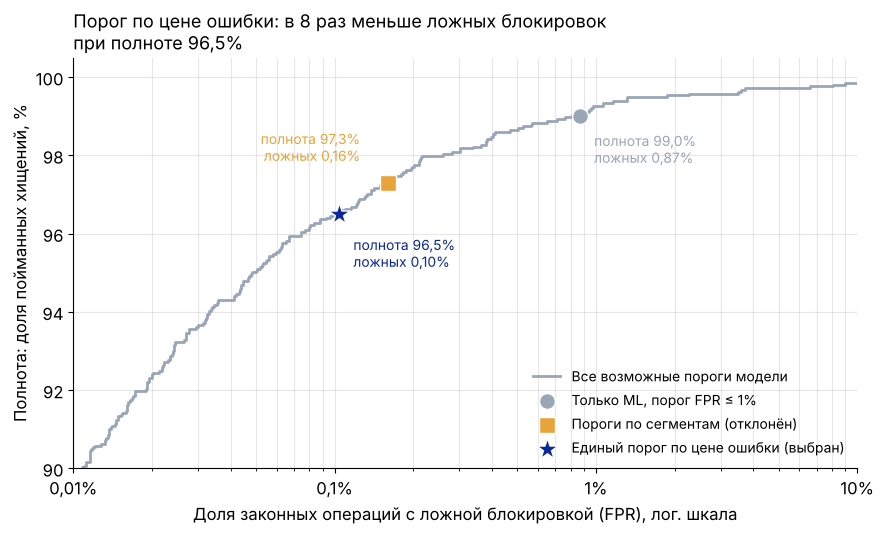

                           recall    FPR    TP    FP
variant                                             
Бейзлайн: FPR ≤ 1%         0.9902 0.0087  2124  4821
Один порог по цене ошибки  0.9650 0.0010  2070   578
Пороги по сегментам        0.9730 0.0016  2087   886


In [14]:
# График для слайда: полнота vs доля ложных блокировок (тест Sparkov)
from sklearn.metrics import roc_curve
plt.rcParams.update({"font.size": 12})
fig, ax = plt.subplots(figsize=(9, 5.5))
fpr, tpr, _ = roc_curve(te.is_fraud, te.score)
ax.plot(fpr * 100, tpr * 100, color="#9aa5b8", lw=2, label="Все возможные пороги модели")
pts = [
    ("Только ML, порог FPR ≤ 1%", "Бейзлайн: FPR ≤ 1%", "o", "#9aa5b8", (10, -34)),
    ("Пороги по сегментам (отклонён)", "Пороги по сегментам", "s", "#e8a33b", (-20, 16)),
    ("Единый порог по цене ошибки (выбран)", "Один порог по цене ошибки", "*", "#0a2896", (10, -38)),
]
for label, key, mk, c, off in pts:
    r = total.loc[key]
    ax.scatter(r.FPR * 100, r.recall * 100, marker=mk, s=260 if mk == "*" else 130, color=c,
               edgecolor="white", zorder=3, label=label)
    ax.annotate(f"полнота {r.recall:.1%}\nложных {r.FPR:.2%}".replace(".", ","),
                (r.FPR * 100, r.recall * 100), xytext=off, textcoords="offset points", fontsize=10, color=c,
                ha="right" if off[0] < 0 else "left")
ax.set_xscale("log"); ax.set_xlim(0.01, 10); ax.set_ylim(max(80, np.floor(total.recall.min() * 100) - 6), 100.5)
ax.set_xticks([0.01, 0.1, 1, 10]); ax.set_xticklabels(["0,01%", "0,1%", "1%", "10%"])
ax.set_xlabel("Доля законных операций с ложной блокировкой (FPR), лог. шкала")
ax.set_ylabel("Полнота: доля пойманных хищений, %")
a, b = total.loc["Бейзлайн: FPR ≤ 1%"], total.loc["Один порог по цене ошибки"]
ax.set_title(f"Порог по цене ошибки: в {a.FPR / b.FPR:.0f} раз меньше ложных блокировок\n"
             f"при полноте {b.recall:.1%}".replace(".", ","), loc="left", fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.grid(alpha=.3, which="both"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", fontsize=10, frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/recall_vs_fpr_slide.png", dpi=200, bbox_inches="tight"); plt.show()
print(total[["recall", "FPR", "TP", "FP"]])

## 5. Сохранение
Относительные изменения и готовые значения для листов «Допущения» и «Цифры в деке».

In [15]:
by_seg.to_csv(f"{OUT_DIR}/thresholds_by_segment.csv", index=False)
total.reset_index().to_csv(f"{OUT_DIR}/thresholds_total.csv", index=False)
ba.to_csv(f"{OUT_DIR}/reaction_before_after.csv")
pd.concat({"AS-IS": asis, "TO-BE": tobe}).to_csv(f"{OUT_DIR}/reaction_by_segment.csv")
grid.to_csv(f"{OUT_DIR}/options_comparison.csv")
sens.to_csv(f"{OUT_DIR}/reaction_sensitivity.csv", index=False)

A, T = asis.loc["все"], tobe.loc["все"]
sheet = pd.DataFrame([
    ["Допущения", 86, "Доля законных операций с сигналом, AS-IS", A.false_signal_rate, "доля"],
    ["Допущения", 87, "Доля законных операций с сигналом, TO-BE", T.false_signal_rate, "доля"],
    ["Допущения", 88, "Доля ошибочно ограниченных законных операций, AS-IS", A.wrongly_restricted_rate, "доля"],
    ["Допущения", 89, "Доля ошибочно ограниченных законных операций, TO-BE", T.wrongly_restricted_rate, "доля"],
    ["Допущения", 90, "Снижение ложных ограничений", 1 - T.wrongly_restricted_exp / A.wrongly_restricted_exp, "доля"],
    ["Допущения", 91, "Снижение хищений", 1 - T.stolen_amount / A.stolen_amount, "доля"],
    ["Допущения", 92, "Снижение потери NPS", 1 - T.nps_penalty_pts / A.nps_penalty_pts, "доля"],
    ["Цифры в деке", 11, "TP: изменение", T.fraud_stopped_exp / A.fraud_stopped_exp - 1, "доля"],
    ["Цифры в деке", 12, "Доля ошибочных ограничений: до", A.wrongly_restricted_rate, "доля"],
    ["Цифры в деке", 12, "Доля ошибочных ограничений: после", T.wrongly_restricted_rate, "доля"],
], columns=["лист", "строка", "показатель", "значение", "ед."])
sheet.to_csv(f"{OUT_DIR}/values_for_sheet.csv", index=False)
sheet

,лист,строка,показатель,значение,ед.
0,Допущения,86,"Доля законных операций с сигналом, AS-IS",0.0010,доля
1,Допущения,87,"Доля законных операций с сигналом, TO-BE",0.0065,доля
2,Допущения,88,"Доля ошибочно ограниченных законных операций, ...",0.0010,доля
3,Допущения,89,"Доля ошибочно ограниченных законных операций, ...",0.0007,доля
4,Допущения,90,Снижение ложных ограничений,0.3025,доля
5,Допущения,91,Снижение хищений,0.0835,доля
6,Допущения,92,Снижение потери NPS,0.2166,доля
7,Цифры в деке,11,TP: изменение,-0.0085,доля
8,Цифры в деке,12,Доля ошибочных ограничений: до,0.0010,доля
9,Цифры в деке,12,Доля ошибочных ограничений: после,0.0007,доля


## Выводы для слайда
**№17. Порог по цене ошибки** (ложная блокировка 222 руб., пропуск = сумма хищения): ложных блокировок 578 вместо 4 821 (**в 8 раз меньше**), полнота 96,5% вместо 99,0%, остановлено 98,7% суммы. Пороги по сегментам дешевле на 4,6% по полной цене, но дают на 53% больше ложных блокировок (886) — отклонены, так как кейс требует снижать ошибочные ограничения.

**№18. Многоуровневая реакция против бинарной приостановки** (тест Sparkov, допущения Р4 от 01.11):
- похищено **−8,4%**;
- ошибочно ограничено **−30,2%** (0,10% → 0,07% законных операций);
- потеря NPS от ошибочных ограничений **−21,7%**;
- TP **−0,85%** — то же число пойманных, но больше остановленных денег;
- обращения в КЦ **+18%** (звонки после подтверждения), итого потери и затраты **−5,6%**.
Чувствительность по 27 сценариям: похищено −4…−12%, ошибочно ограничено −28…−61%, итоговые потери −2…−10% — вывод устойчив.

**№32. Сравнение вариантов:** только правила пропускают 21% суммы; только ML блокирует законные операции в 12 раз чаще выбранного и не выполняет обязательные признаки ЦБ; выбранный гибрид с многоуровневой реакцией даёт наименьшие потери (2,46 млн руб. против 2,60 у гибрида с единым порогом) и наименьшую долю ошибочных ограничений (0,07%).